# 02 — Logistic Regression Baseline

**Purpose:** Build the simplest model as a comparable baseline. All later models (random forest / XGBoost) are compared against it.

**Method:**
- Split: stratified train/test split, 80/20, with a fixed `random_state=42`. The test set is held out once and is never used to choose between models.
- Model selection (defect 5): baseline vs `class_weight="balanced"` are compared with 5-fold stratified cross-validation **inside the training data only** (CV AUC, with CV recall as a secondary check). The winner is then fitted on the full training set and evaluated **once** on the final test set. CV metrics and final-test metrics are labelled separately in `reports/model_results.csv` and must not be compared as if they were the same thing.
- Preprocessing (defect 2): `SimpleImputer(strategy="median")` sits **inside** the numeric sklearn pipeline, so it is fitted only on training data. No imputation is learned from the whole dataset before the split.
- Encoding (defect 4): one-hot encoding with `drop="first"`; the dropped category of each categorical variable is its reference category (see the coefficient section). Coefficients are conditional associations, not independent causal effects, and correlated delay features make individual coefficients unstable — do not interpret them one by one as causal.
- Evaluation: AUC, recall (default class), precision (default class), confusion matrix, and accuracy. **Accuracy is for reference only and must be reported together with the other metrics** — default is the minority class (about 22%), so predicting "no default" for everyone would still give high accuracy but zero value.
- Classification threshold: 0.5 by default. Moving the threshold trades recall against precision, which is a core interview question for Credit Risk roles.


## 0. Read the feature table

Read `credit_features.csv` produced by `01_eda.ipynb`. First check its shape, dtypes, and missing values, and compare them with the SQL validation results.


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Find the project root: works whether run from notebooks/ or from the project root
_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p for p in _CANDIDATES if (p / "data" / "processed" / "credit_features.csv").exists()),
    Path.cwd().parent,
)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from features import NUMERIC_FEATURES, CATEGORICAL_FEATURES, assert_features_schema

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)
print("Feature file:", PROCESSED_DIR / "credit_features.csv")


Project root: /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/clean-verification
Feature file: /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/clean-verification/data/processed/credit_features.csv


In [2]:
features = pd.read_csv(PROCESSED_DIR / "credit_features.csv")
print("Shape (rows, columns):", features.shape)
print("Total missing values:", int(features.isna().sum().sum()))
print("Target default rate:", round(features["default_payment_next_month"].mean() * 100, 2), "%")
features.head(3)

Shape (rows, columns): (30000, 36)
Total missing values: 3669
Target default rate: 22.12 %


,ID,LIMIT_BAL,SEX,education_code,education_label,marriage_code,marriage_label,AGE,BILL_AMT1,BILL_AMT2,...,default_payment_next_month,utilisation_1,pay_ratio_1,pay_ratio_avg,pay_ratio_1_denominator_le_0,pay_ratio_avg_denominator_le_0,max_delay_6m,delay_months_cnt,consecutive_delay,bill_trend
0,1,20000,2,2,University,1,Married,24,3913,3102,...,1,0.195650,0.000000,0.089434,0,0,2,2,2,3913
1,2,120000,2,2,University,2,Single,26,2682,1725,...,1,0.022350,0.000000,0.292791,0,0,2,2,0,-579
2,3,90000,2,2,University,2,Single,34,29239,14027,...,0,0.324878,0.051917,0.108388,0,0,0,0,0,13690


## 1. Features and split

- Numeric features: credit limit, age, 6 months of bill / repayment amounts, 6 delay-month values, and the derived features from notebook 01 — including the two denominator flags (`pay_ratio_1_denominator_le_0`, `pay_ratio_avg_denominator_le_0`).
- Categorical features: sex, education label, and marital status label (unknown categories already merged, see `sql/README.md`).
- Missing ratio values are **not** filled before the split. `SimpleImputer(strategy="median")` is inside the numeric pipeline and is fitted only on training data (defect 2).
- Model choice is made with cross-validation inside the training data only; the test set is evaluated once, for the selected model only (defect 5).
- Stratified 80/20 split, `random_state=42`. The train and test default rates should be close.


In [3]:
numeric_features = list(NUMERIC_FEATURES)
categorical_features = list(CATEGORICAL_FEATURES)

features = pd.read_csv(PROCESSED_DIR / "credit_features.csv")
assert_features_schema(features)

X = features[numeric_features + categorical_features].copy()
y = features["default_payment_next_month"]

# Split BEFORE learning any imputation values (defect 2).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Training set: {len(X_train):,} rows, default rate {y_train.mean() * 100:.2f}%")
print(f"Test set: {len(X_test):,} rows, default rate {y_test.mean() * 100:.2f}%")
print(f"Number of features: {X.shape[1]} (numeric {len(numeric_features)} + categorical {len(categorical_features)})")
print(f"Pre-imputation missing in train: pay_ratio_1={int(X_train['pay_ratio_1'].isna().sum())}, "
      f"pay_ratio_avg={int(X_train['pay_ratio_avg'].isna().sum())}")


Training set: 24,000 rows, default rate 22.12%
Test set: 6,000 rows, default rate 22.12%
Number of features: 32 (numeric 29 + categorical 3)
Pre-imputation missing in train: pay_ratio_1=2080, pay_ratio_avg=855


## 2. Model selection with cross-validation (training data only)

Compare the two candidates with 5-fold stratified CV inside the training data. Selection rule, fixed before seeing the test set: the higher CV AUC wins; CV recall is the secondary check. The test set plays no part in this choice (defect 5).


/home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


/home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic regression (baseline): CV AUC 0.7692, CV recall 0.3692, CV precision 0.6605, CV accuracy 0.8185


... (4 outputs left out)

/home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic regression (class_weight=balanced): CV AUC 0.7700, CV recall 0.6125, CV precision 0.4699, CV accuracy 0.7613

Selected by CV AUC: Logistic regression (class_weight=balanced)


/home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(



Final test metrics for the selected model (Logistic regression (class_weight=balanced), threshold 0.5):
  AUC: 0.7539
  Recall (default): 0.5818
  Precision (default): 0.4555
  Accuracy: 0.7537

Confusion matrix (rows = actual, columns = predicted; 0 = no default, 1 = default):
          Predicted 0  Predicted 1
Actual 0         3750          923
Actual 1          555          772


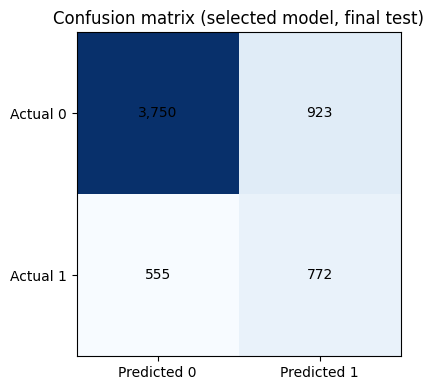

In [4]:
def make_pipeline(class_weight=None):
    return Pipeline([
        ("preprocess", ColumnTransformer([
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric_features),
            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
             categorical_features),
        ])),
        ("clf", LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=42)),
    ])

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"auc": "roc_auc", "recall": "recall", "precision": "precision", "accuracy": "accuracy"}

candidates = {
    "Logistic regression (baseline)": make_pipeline(None),
    "Logistic regression (class_weight=balanced)": make_pipeline("balanced"),
}
cv_rows = []
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name, "Split": "CV (train only, 5-fold)"}
    for k in ["auc", "recall", "precision", "accuracy"]:
        row[{"auc": "AUC", "recall": "Recall (default)", "precision": "Precision (default)", "accuracy": "Accuracy"}[k]] = float(res[f"test_{k}"].mean())
    cv_rows.append(row)
    print(f"{name}: CV AUC {row['AUC']:.4f}, CV recall {row['Recall (default)']:.4f}, "
          f"CV precision {row['Precision (default)']:.4f}, CV accuracy {row['Accuracy']:.4f}")

cv_df = pd.DataFrame(cv_rows)
# Selection: higher CV AUC wins; CV recall breaks a near-tie (<0.001).
best_idx = int(cv_df["AUC"].idxmax())
selected_name = cv_df.loc[best_idx, "Model"]
print()
print(f"Selected by CV AUC: {selected_name}")

# Fit the selected approach on the full training set, then evaluate ONCE on the test set.
model = candidates[selected_name]
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "AUC": roc_auc_score(y_test, y_proba),
    "Recall (default)": recall_score(y_test, y_pred),
    "Precision (default)": precision_score(y_test, y_pred),
    "Accuracy": accuracy_score(y_test, y_pred),
}
print()
print(f"Final test metrics for the selected model ({selected_name}, threshold 0.5):")
for k, v in metrics.items():
    print(f"  {k}: {v:.4f}")

cm = confusion_matrix(y_test, y_pred)
print()
print("Confusion matrix (rows = actual, columns = predicted; 0 = no default, 1 = default):")
print(pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]).to_string())

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Predicted 0", "Predicted 1"])
ax.set_yticklabels(["Actual 0", "Actual 1"])
ax.set_title("Confusion matrix (selected model, final test)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
plt.tight_layout()
plt.show()


## 3. Coefficient direction check: does it match common sense?

Look at the largest positive / negative coefficients: delay-related features (for example `max_delay_6m` and `consecutive_delay`) should be positive (more delay means a higher chance of default); a higher repayment ratio should be negative. If a direction is reversed, first suspect the encoding or feature definition — do not accept it as given.

**Reference categories (defect 4):** `OneHotEncoder(drop="first")` drops the first category of each categorical variable, so every other category's coefficient is measured *relative to that reference*, holding the other features in the model fixed. The references are printed below and are determined by the encoder, not assumed.

**Do not read coefficients as independent causal effects.** The raw and derived delay features (`PAY_*`, `pay_*_delay_months`, `max_delay_6m`, `delay_months_cnt`, `consecutive_delay`) are strongly correlated, so their coefficients share the same signal and are individually unstable — for example `consecutive_delay` can carry a negative coefficient even though delay itself raises default risk, because `delay_months_cnt` and related fields already carry most of that signal. Treat the coefficients as a joint, descriptive pattern, not as "changing this one thing by itself causes this change in default risk".


Selected model: Logistic regression (class_weight=balanced)
Reference categories (dropped first category per variable):
  SEX: reference = np.int64(1); encoded = [np.int64(2)]
  education_label: reference = 'Graduate school'; encoded = ['High school', 'Others / Unknown', 'University']
  marriage_label: reference = 'Married'; encoded = ['Others / Unknown', 'Single']

Top 12 coefficients by absolute value (selected model, final test fit):
                              feature  coefficient
cat__education_label_Others / Unknown    -0.929917
                num__delay_months_cnt     0.773332
              num__pay_0_delay_months     0.520395
               num__consecutive_delay    -0.291436
                       num__LIMIT_BAL    -0.221162
  num__pay_ratio_avg_denominator_le_0     0.185865
                    num__max_delay_6m     0.179986
           cat__marriage_label_Single    -0.150967
                           cat__SEX_2    -0.137099
                        num__PAY_AMT1    -0.12761

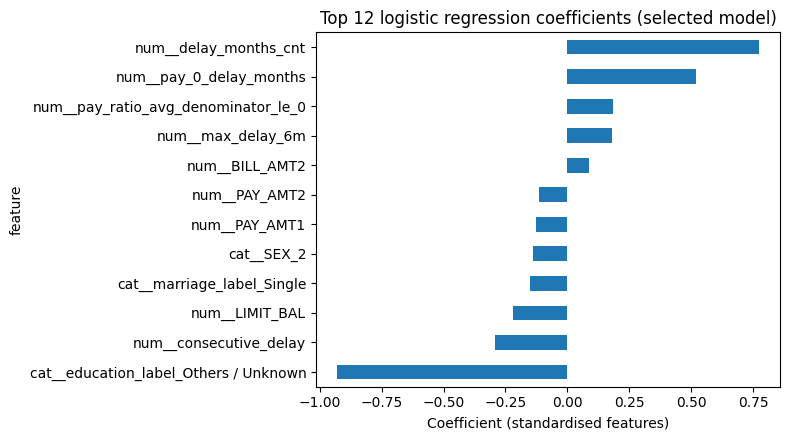

In [5]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefs = model.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": feature_names, "coefficient": coefs})
coef_df["abs_coef"] = coef_df["coefficient"].abs()
top = coef_df.sort_values("abs_coef", ascending=False).head(12).drop(columns="abs_coef")
print("Selected model:", selected_name)
print("Reference categories (dropped first category per variable):")
cat_encoder = model.named_steps["preprocess"].named_transformers_["cat"]
for var, cats in zip(categorical_features, cat_encoder.categories_):
    print(f"  {var}: reference = {cats[0]!r}; encoded = {list(cats[1:])}")
print()
print("Top 12 coefficients by absolute value (selected model, final test fit):")
print(top.to_string(index=False))

ax = top.sort_values("coefficient").plot(kind="barh", x="feature", y="coefficient",
                                         figsize=(8, 4.5), legend=False)
ax.set_title("Top 12 logistic regression coefficients (selected model)")
ax.set_xlabel("Coefficient (standardised features)")
plt.tight_layout()
plt.show()


## 4. What the CV comparison showed

The two candidates were compared with cross-validation inside the training data only (section 2). The balanced version is expected to raise recall at the cost of precision; whether that trade-off is worth it depends on business cost — missing a defaulter means a direct credit loss, while a false positive means an approval cost. The final test set was used once, for the selected model only, so the test metrics in section 2 are not the basis on which the model was chosen.


In [6]:
print(cv_df.round(4).to_string(index=False))
print()
print(f"Selected model: {selected_name}")
print("Final test metrics (selected model only):")
for k, v in metrics.items():
    print(f"  {k}: {v:.4f}")


                                      Model                   Split    AUC  Recall (default)  Precision (default)  Accuracy
             Logistic regression (baseline) CV (train only, 5-fold) 0.7692            0.3692               0.6605    0.8185
Logistic regression (class_weight=balanced) CV (train only, 5-fold) 0.7700            0.6125               0.4699    0.7613

Selected model: Logistic regression (class_weight=balanced)
Final test metrics (selected model only):
  AUC: 0.7539
  Recall (default): 0.5818
  Precision (default): 0.4555
  Accuracy: 0.7537


## 5. Write out the model results table

Save it to `reports/model_results.csv`. The `Split` column labels CV (train only) versus final-test rows, so the two kinds of metric are never mixed up. Power BI page 3 reads the final-test row of the selected model.


In [7]:
final_row = {"Model": selected_name, "Split": "Final test (selected model only)", **metrics,
             "Notes": "threshold 0.5; stratified 80/20, random_state=42; selected by 5-fold CV AUC on train only"}
results = pd.concat([cv_df.assign(Notes="5-fold stratified CV on train only, random_state=42"),
                     pd.DataFrame([final_row])], ignore_index=True)
results = results[["Model", "Split", "AUC", "Recall (default)", "Precision (default)", "Accuracy", "Notes"]]
results_path = REPORTS_DIR / "model_results.csv"
results.to_csv(results_path, index=False)
print("Saved to:", results_path)
print(results.round(4).to_string(index=False))


Saved to: /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/clean-verification/reports/model_results.csv
                                      Model                            Split    AUC  Recall (default)  Precision (default)  Accuracy                                                                                     Notes
             Logistic regression (baseline)          CV (train only, 5-fold) 0.7692            0.3692               0.6605    0.8185                                       5-fold stratified CV on train only, random_state=42
Logistic regression (class_weight=balanced)          CV (train only, 5-fold) 0.7700            0.6125               0.4699    0.7613                                       5-fold stratified CV on train only, random_state=42
Logistic regression (class_weight=balanced) Final test (selected model only) 0.7539            0.5818               0.4555    0.7537 threshold 0.5; stratified 80/20, random_state

## Next steps

- `03_tree_models.ipynb` (to do): random forest, then XGBoost if time allows; keep tuning to a small range and do not over-tune for score. Future models must use the same protocol as here — select with cross-validation inside the training data and evaluate once on this same test set — and must not use repeated test results to choose between models.
- Threshold trade-off: the default 0.5 is not necessarily right for imbalanced data. Try how changing the threshold affects recall / precision on validation data, and note which threshold you choose and why.
